
# Assignment 8 — Memory Agent Using LangGraph

### Objective
Implement a memory agent that stores the **last user command** and can repeat it when requested.

### Agent Approach
This assignment uses **LangGraph** to organize the agent as a simple state-based workflow.

The agent can:
- Store a new command in memory.
- Repeat the last stored command.
- Clear its memory.
- Maintain its state across multiple interactions.

This demonstrates the basic idea of **memory in an AI agent**.


### Step 1 — Install and Import Libraries
LangGraph is used to create the memory-agent workflow.

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time



### Step 2 — Define the Agent State

The state contains the current user command, the stored memory, and the response generated by the agent.


In [ ]:

class MemoryState(TypedDict, total=False):
    command: str
    memory: str
    response: str
    action: str



### Step 3 — Create the Memory Agent Nodes

The agent decides what to do based on the user's command.

- A normal command is stored in memory.
- `repeat` returns the stored command.
- `clear` removes the stored command.


In [ ]:

def process_command(state):
    command = state["command"].strip()
    lower_command = command.lower()

    if lower_command in ["repeat", "repeat last", "last command"]:
        state["action"] = "repeat"

    elif lower_command in ["clear", "clear memory"]:
        state["action"] = "clear"

    else:
        state["action"] = "store"

    return state


def update_memory(state):
    command = state["command"].strip()

    if state["action"] == "store":
        state["memory"] = command
        state["response"] = f"Stored in memory: {command}"

    elif state["action"] == "repeat":
        if state.get("memory"):
            state["response"] = f"Last command: {state['memory']}"
        else:
            state["response"] = "Memory is empty."

    elif state["action"] == "clear":
        state["memory"] = ""
        state["response"] = "Memory cleared."

    return state


### Step 4 — Build the LangGraph Workflow
The workflow processes the command and then updates or reads the agent's memory.

In [ ]:

workflow = StateGraph(MemoryState)

workflow.add_node("process_command", process_command)
workflow.add_node("update_memory", update_memory)

workflow.add_edge(START, "process_command")
workflow.add_edge("process_command", "update_memory")
workflow.add_edge("update_memory", END)

memory_agent = workflow.compile()

print("LangGraph memory workflow created successfully.")


LangGraph memory workflow created successfully.



### Step 5 — Test the Memory Agent

We first store a command and then ask the agent to repeat it.


In [ ]:

memory = ""

result = memory_agent.invoke({
    "command": "Open my project folder",
    "memory": memory
})

memory = result["memory"]
print(result["response"])

result = memory_agent.invoke({
    "command": "repeat",
    "memory": memory
})

memory = result["memory"]
print(result["response"])


Stored in memory: Open my project folder
Last command: Open my project folder



### Step 6 — Test Multiple Commands

The agent should always remember only the **most recent normal command**.


In [ ]:

commands = [
    "Check my assignments",
    "Start the Python program",
    "Save the project",
    "repeat"
]

memory = ""

for command in commands:
    result = memory_agent.invoke({
        "command": command,
        "memory": memory
    })

    memory = result["memory"]
    print("User:", command)
    print("Agent:", result["response"])
    print()


User: Check my assignments
Agent: Stored in memory: Check my assignments

User: Start the Python program
Agent: Stored in memory: Start the Python program

User: Save the project
Agent: Stored in memory: Save the project

User: repeat
Agent: Last command: Save the project




### Step 7 — Check Memory Clearing

The `clear` command removes the stored command. After clearing, `repeat` should report that the memory is empty.


In [ ]:

memory = ""

result = memory_agent.invoke({
    "command": "Submit the assignment",
    "memory": memory
})
memory = result["memory"]
print("Agent:", result["response"])

result = memory_agent.invoke({
    "command": "clear",
    "memory": memory
})
memory = result["memory"]
print("Agent:", result["response"])

result = memory_agent.invoke({
    "command": "repeat",
    "memory": memory
})
memory = result["memory"]
print("Agent:", result["response"])


Agent: Stored in memory: Submit the assignment
Agent: Memory cleared.
Agent: Memory is empty.


### Step 8 — Visualize Memory Changes
The graph shows whether the agent currently has a stored command.

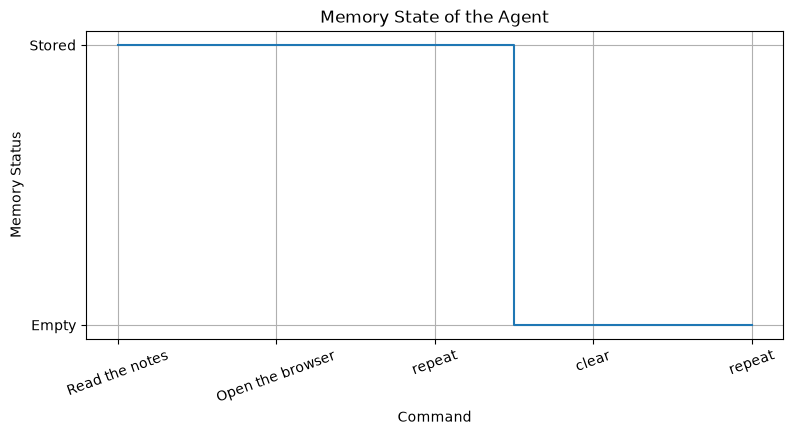

In [ ]:

test_commands = [
    "Read the notes",
    "Open the browser",
    "repeat",
    "clear",
    "repeat"
]

memory = ""
memory_status = []

for command in test_commands:
    result = memory_agent.invoke({
        "command": command,
        "memory": memory
    })

    memory = result["memory"]
    memory_status.append(1 if memory else 0)

plt.figure(figsize=(9, 4))
plt.step(range(1, len(memory_status) + 1), memory_status, where="mid")
plt.yticks([0, 1], ["Empty", "Stored"])
plt.xticks(range(1, len(test_commands) + 1), test_commands, rotation=20)
plt.xlabel("Command")
plt.ylabel("Memory Status")
plt.title("Memory State of the Agent")
plt.grid(True)
plt.show()


### Step 9 — Display the Current Memory

In [ ]:

print("Current memory:")
print(memory if memory else "Memory is empty.")


Current memory:
Memory is empty.



### Step 10 — Interactive Memory Agent

Enter commands interactively.

Special commands:
- `repeat` — repeat the last stored command
- `clear` — clear the memory
- `exit` — stop the program


In [ ]:

# memory = ""

# while True:
#     command = input("You: ").strip()

#     if command.lower() == "exit":
#         print("Agent: Goodbye!")
#         break

#     result = memory_agent.invoke({
#         "command": command,
#         "memory": memory
#     })

#     memory = result["memory"]
#     print("Agent:", result["response"])


Agent: Stored in memory: 
Agent: Stored in memory: 
Agent: Stored in memory: 
Agent: Stored in memory: 
Agent: Stored in memory: Escape
Agent: Stored in memory: ENter
Agent: Stored in memory: Enter
Agent: Stored in memory: 
Agent: Stored in memory: 
Agent: Stored in memory: 
Agent: Stored in memory: 
Agent: Stored in memory: 



### Step 11 — Simple Memory Demonstration

The following animation demonstrates the memory changing as commands are processed.


In [ ]:

demo_commands = [
    "Study Python",
    "Complete the project",
    "repeat",
    "clear"
]

memory = ""

for command in demo_commands:
    result = memory_agent.invoke({
        "command": command,
        "memory": memory
    })

    memory = result["memory"]

    clear_output(wait=True)
    print("User command:", command)
    print("Agent response:", result["response"])
    print()
    print("Stored memory:", memory if memory else "[empty]")

    time.sleep(1)

print("Demonstration completed.")



### Result

The LangGraph memory agent successfully stores the latest user command, repeats it when requested, and clears it when instructed.

### Conclusion

This assignment demonstrates a simple **memory agent using LangGraph**. The graph provides the processing workflow, while the state variable maintains the agent's short-term memory between interactions.

The agent therefore shows how state can be maintained and used to make future responses depend on previous commands.
